<a href="https://colab.research.google.com/github/devinlin2022/Kanban2/blob/main/Predictive_Maintaineance_Devin_Lin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Target Percentage Distribution:
Target
0    96.61
1     3.39
Name: proportion, dtype: float64


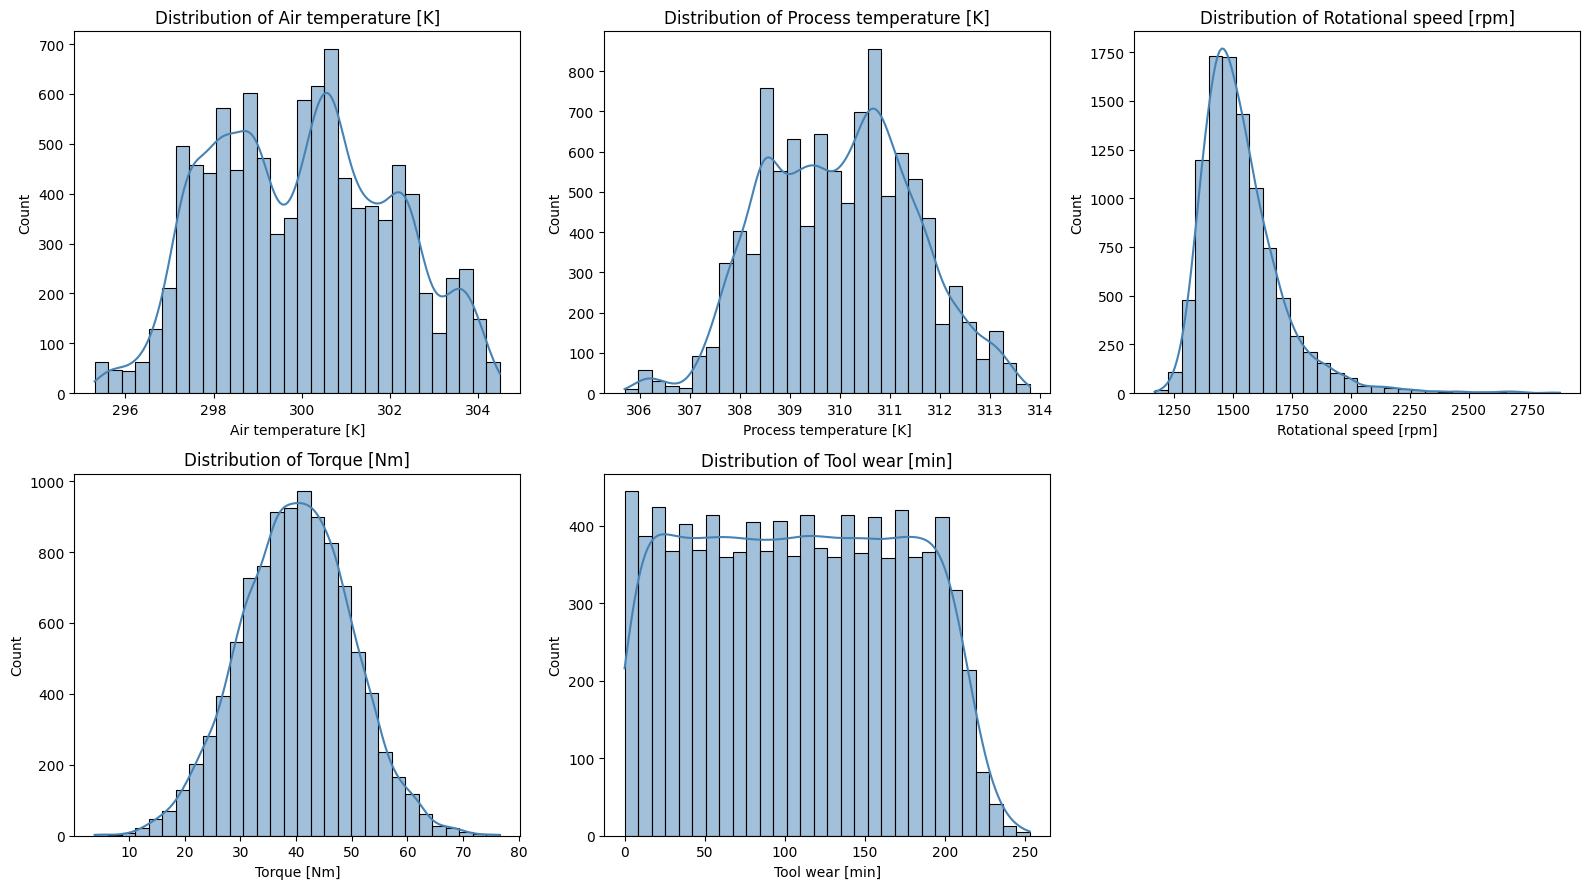

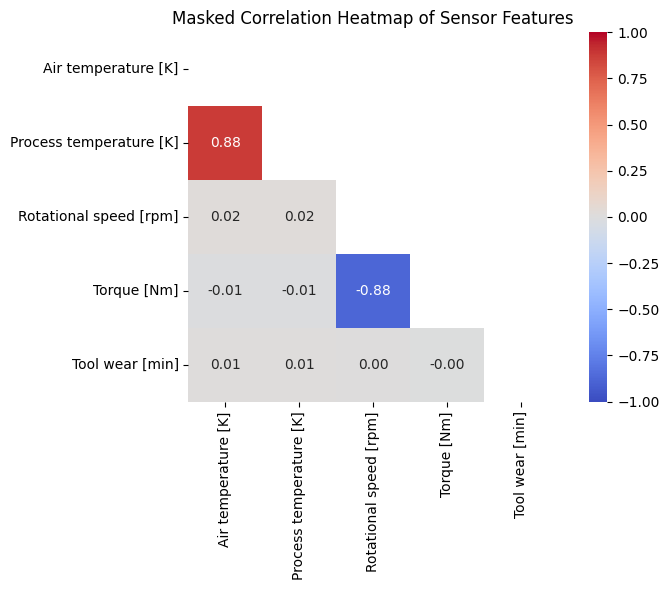

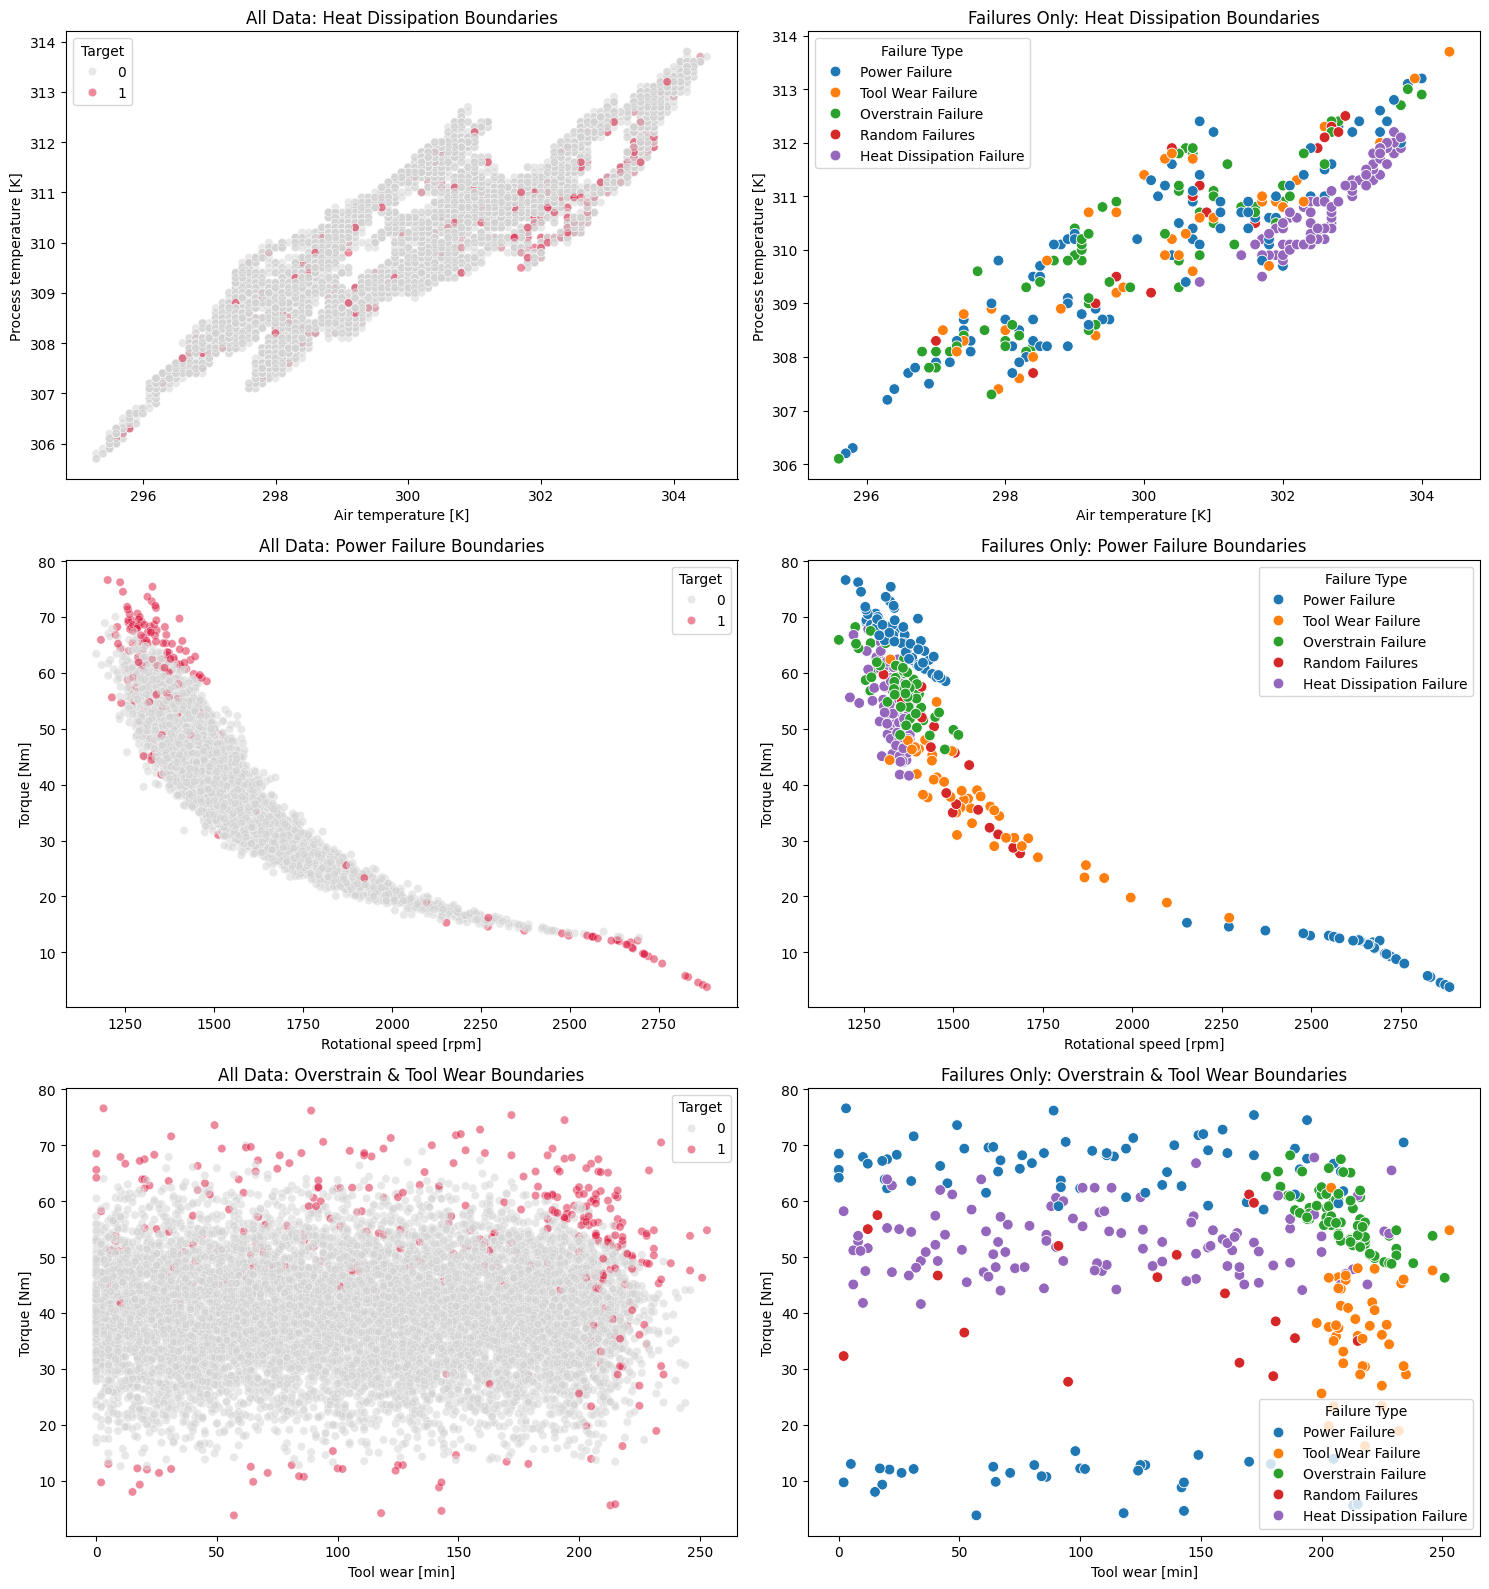

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



df = pd.read_csv('/content/sensor_telemetry_data.csv')
target_pct = df['Target'].value_counts(normalize=True) * 100
print("Target Percentage Distribution:")
print(target_pct.round(2))

num_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for idx, col in enumerate(num_features):
    sns.histplot(df[col], kde=True, ax=axes[idx], color='steelblue', bins=30)
    axes[idx].set_title(f'Distribution of {col}')
axes[5].axis('off')
plt.tight_layout()
plt.show()

corr_matrix = df[num_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True
)
plt.title('Masked Correlation Heatmap of Sensor Features')
plt.tight_layout()
plt.show()

failures_df = df[df['Failure Type'] != 'No Failure']
feature_pairs = [
    ('Air temperature [K]', 'Process temperature [K]', 'Heat Dissipation Boundaries'),
    ('Rotational speed [rpm]', 'Torque [Nm]', 'Power Failure Boundaries'),
    ('Tool wear [min]', 'Torque [Nm]', 'Overstrain & Tool Wear Boundaries')
]

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for row_idx, (x_col, y_col, title_suffix) in enumerate(feature_pairs):
    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col,
        hue='Target',
        palette={0: 'lightgray', 1: 'crimson'},
        alpha=0.5,
        ax=axes[row_idx, 0]
    )
    axes[row_idx, 0].set_title(f'All Data: {title_suffix}')

    sns.scatterplot(
        data=failures_df,
        x=x_col,
        y=y_col,
        hue='Failure Type',
        palette='tab10',
        s=60,
        ax=axes[row_idx, 1]
    )
    axes[row_idx, 1].set_title(f'Failures Only: {title_suffix}')

plt.tight_layout()
plt.show()


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

df = pd.read_csv('/content/sensor_telemetry_data.csv')
X = df.drop(columns=['SKU', 'Failure Type', 'Target'])
y = df['Target']

num_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]
cat_features = ['Type']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first'), cat_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set row count: {len(X_train)}")
print(f"Testing set row count: {len(X_test)}")

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

Training set row count: 8000
Testing set row count: 2000


In [11]:
print("Class counts before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

print("Class counts after SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Class counts before SMOTE:
Target
0    7729
1     271
Name: count, dtype: int64
Class counts after SMOTE:
Target
0    7729
1    7729
Name: count, dtype: int64


In [13]:

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)
from imblearn.over_sampling import SMOTE

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'MLP Classifier': MLPClassifier(random_state=42, max_iter=500)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    y_pred = model.predict(X_test_processed)
    score = f1_score(y_test, y_pred)
    trained_models[name] = model
    print(f"{name} Test F1-Score: {score:.4f}")

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 15, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train_smote, y_train_smote)

tuned_rf = grid_search.best_estimator_
baseline_f1 = f1_score(y_test, trained_models['Random Forest'].predict(X_test_processed))
tuned_f1 = f1_score(y_test, tuned_rf.predict(X_test_processed))

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Baseline Random Forest F1-Score: {baseline_f1:.4f}")
print(f"Tuned Random Forest F1-Score: {tuned_f1:.4f}")

Logistic Regression Test F1-Score: 0.2467
Decision Tree Test F1-Score: 0.4569
Random Forest Test F1-Score: 0.6190
Gradient Boosting Test F1-Score: 0.4688
MLP Classifier Test F1-Score: 0.5759


KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
quadrant_labels = np.array([['TN', 'FP'], ['FN', 'TP']])

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_processed)
    cm = confusion_matrix(y_test, y_pred)
    annot_matrix = np.empty(cm.shape, dtype=object)
    for i in range(2):
        for j in range(2):
            annot_matrix[i, j] = f"{quadrant_labels[i, j]}\n{cm[i, j]}"

    sns.heatmap(
        cm,
        annot=annot_matrix,
        fmt='',
        cmap='Blues',
        cbar=False,
        ax=axes[idx],
        xticklabels=['Pred 0', 'Pred 1'],
        yticklabels=['Actual 0', 'Actual 1']
    )
    axes[idx].set_title(name)

axes[5].axis('off')
plt.tight_layout()
plt.show()

all_models_for_roc = dict(trained_models)
all_models_for_roc['Tuned Random Forest'] = tuned_rf

plt.figure(figsize=(10, 7))
for name, model in all_models_for_roc.items():
    y_prob = model.predict_proba(X_test_processed)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves Across All Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
baseline_cost = 68 * 5000
    print(f"Baseline (Doing Nothing) Cost: ${baseline_cost:,.2f}")

    eval_models = {
        'Logistic Regression': trained_models['Logistic Regression'],
        'Tuned Random Forest': tuned_rf
    }

    for name, model in eval_models.items():
        y_pred = model.predict(X_test_processed)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        total_cost = (fp * 100) + (fn * 5000)
        savings = baseline_cost - total_cost
        print(
            f"{name} -> FP: {fp}, FN: {fn} | "
            f"Total Cost: ${total_cost:,.2f} | Savings: ${savings:,.2f}"
        )

    X_multi = df.drop(columns=['SKU', 'Failure Type', 'Target'])
    y_multi = df['Failure Type']

    X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
        X_multi,
        y_multi,
        test_size=0.20,
        random_state=42,
        stratify=y_multi
    )

    X_train_m_proc = preprocessor.fit_transform(X_train_m)
    X_test_m_proc = preprocessor.transform(X_test_m)

    multi_rf = RandomForestClassifier(class_weight='balanced', random_state=42)
    multi_rf.fit(X_train_m_proc, y_train_m)
    y_pred_m = multi_rf.predict(X_test_m_proc)

    print("Multi-Class Classification Report:")
    print(classification_report(y_test_m, y_pred_m, zero_division=0))

    labels = sorted(y_multi.unique())
    cm_multi = confusion_matrix(y_test_m, y_pred_m, labels=labels)

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm_multi,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels
    )
    plt.xlabel('Predicted Failure Type')
    plt.ylabel('Actual Failure Type')
    plt.title('Multi-Class Confusion Matrix (Failure Type)')
    plt.xticks(rotation=30, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
df = run_task_1('sensor_telemetry_data.csv')
X_train_processed, X_test_processed, y_train, y_test, preprocessor = run_task_2(df)
X_train_smote, y_train_smote = run_task_3(X_train_processed, y_train)
trained_models, tuned_rf = run_task_4(X_train_smote, y_train_smote, X_test_processed, y_test)
run_task_5(trained_models, tuned_rf, X_test_processed, y_test)
run_task_6(df, trained_models, tuned_rf, X_test_processed, y_test, preprocessor)